# Lumen-Aware Calibration on the Group Base Model (DAv2 Small + Smooth Correction)

**Base model (same as the group):** DAv2 Small 518 + smooth correction, fitted on mask-A pixels
(group base, `results/DAv2_MaskA_Verified`). Predictions: official DAv2 code, `infer_image(input_size=518)`
(`results/E/refinement/smooth_model.py`):
- linear calibration: depth = clip(−scale · pred + offset, 1e-3, 100), OLS of GT on −pred over all mask-A pixels
- smooth correction: depth = clip(depth + interp(depth, [10, 30, 50, 70], corrections), 1e-3, 100), corrections =
  mean (GT − linear) of mask-A pixels in bins of linear depth (first four bins)

**Aim:** test if a correction that knows where the dark, far lumen is can improve the group base depth *D0*.
Each method corrects *D0*; no method replaces the base.

## Methods
| # | Method | Depth |
|---|---|---|
| 0 | Base: Small + smooth (group, mask A) | D0 = apply_smooth(pred, params) |
| 1 | + lumen-aware residual (darkness) | D0 + (1 − w) · r_wall(D0) + w · r_lumen(D0), cue = darkness |
| 2 | + lumen-aware residual (depth) | same, cue = far (rank of −pred) |
| 3 | + lumen-aware residual (both) | same, cue = √(dark · far) |
| 4 | + isotonic (log) | exp(f(D0)), f = isotonic fit of log(GT) on D0 |
| 5 | + lumen-aware isotonic (log) | exp((1 − w) · f_wall(D0) + w · f_lumen(D0)), cue = both |

The residual curves r are the mean signed error (GT − D0) in bins of D0 ([0, 20, 40, 60, 80, 100] mm, centres 10…90 mm),
weighted by 1 − w (wall) or w (lumen). A bin with a weighted count < 2000 gets a correction of 0.
The lumen map *w* uses no ground truth (same detector as `Final_Lumen_model.ipynb`).

## Protocol
- **Dev (trans_t1_a, 61 frames):** 4-block CV with a 2-frame gap (`common.dev_folds`). In each fold the base is
  also refitted with `fit_base_maskA` on the fit frames only; then methods 1–5 are fitted on the same frames.
- **Test (trans_t2_b, 103 frames):** base = frozen mask-A group parameters
  (`results/DAv2_MaskA_Verified/calibration_parameters_maskA.json`); methods 1–5 fitted on all 61 dev frames.
  Run **once**, in its own cell, only when `RUN_TEST = True`.
- **Checks:** (a) `fit_base_maskA` on all 61 dev frames reproduces the frozen mask-A parameters (within 0.01);
  (b) the base on test, mask A, frame mean, gives AbsRel 0.2805 (as in `DAv2_MaskA_Verified`).
- Masks: **A** = 0 < raw < 65535 and RGB max > 10 (tables); **B** = raw > 0 (keeps the clipped 100 mm pixels;
  saved in the CSV files only).
- Metrics (`common.compute_metrics` / `common.aggregate`): AbsRel, RMSE, MAE (mm), δ < 1.25; also AbsRel in the
  wall (w ≤ 0.5) and in the lumen (w > 0.5).

## 1. Settings
`RUN_TEST` is the only switch. Keep it `False` until all dev work is final; the test cell (Section 9) runs the test only
when `RUN_TEST` is True and `test_done.json` does not exist. Once the test has run, the notebook shows the saved test
results and does not re-save the dev files (so that re-running all cells changes nothing in `results/`).

In [1]:
RUN_TEST = False                    # set to True only for the single final test run (Section 9)

import sys; sys.path.insert(0, "..")
from common import (CFG, DEVICE, SEED, DEPTH_MAX_MM, REPO_ROOT, list_frames, make_mask, compute_metrics,
                    aggregate, dev_folds, save_run_info, save_summary, stream_results_dir)

import json
from datetime import datetime

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm
from scipy import ndimage
from sklearn.isotonic import IsotonicRegression
from tqdm import tqdm

# ---- Settings ----
RUN_NAME   = "LumenAware_on_SmallSmooth"
INPUT_SIZE = 518                                     # same as the group model
DMAX       = DEPTH_MAX_MM                            # 100 mm
BIN_EDGES  = np.array([0, 20, 40, 60, 80, 100], dtype=np.float64)
CENTERS    = (BIN_EDGES[:-1] + BIN_EDGES[1:]) / 2    # 10, 30, 50, 70, 90 mm
MIN_PIXELS = 2000                                    # minimum weighted pixels in a residual bin
FIT_STRIDE = 4                                       # residual curves: every 4th mask-A pixel
ISO_STRIDE = 16                                      # isotonic fits: every 16th mask-A pixel
N_BLOCKS, GAP = 4, 2                                 # block CV (common.dev_folds)
CUES       = ["dark", "far", "both"]
SIGMA, TAU = 20, 0.5                                 # lumen detector (fixed, not fitted)
MASKS      = ["A", "B"]

out_dir   = stream_results_dir(CFG, RUN_NAME)        # results/LumenAware_on_SmallSmooth
fig_dir   = out_dir / "figures"
fig_dir.mkdir(exist_ok=True)
TEST_DONE = out_dir / "test_done.json"
CACHE     = REPO_ROOT / "results" / "E" / "refinement" / "cache"           # shared DAv2 Small predictions
BASE_PARAMS = REPO_ROOT / "results" / "DAv2_MaskA_Verified" / "calibration_parameters_maskA.json"
dev_paths  = list_frames(CFG, "dev")                 # trans_t1_a
test_paths = list_frames(CFG, "test")                # trans_t2_b

# ---- Methods: (label, kind, cue) ----
BASE, FINAL = "Base: Small + smooth (group, mask A)", "+ lumen-aware isotonic (log)"
METHODS = [
    (BASE,                                "base",      None),
    ("+ lumen-aware residual (darkness)", "resid",     "dark"),
    ("+ lumen-aware residual (depth)",    "resid",     "far"),
    ("+ lumen-aware residual (both)",     "resid",     "both"),
    ("+ isotonic (log)",                  "iso",       None),
    (FINAL,                               "iso_lumen", "both"),
]
LABELS = [m[0] for m in METHODS]
COLORS = dict(zip(LABELS, ["#e0a030", "#a9cdb4", "#6aa486", "#2e6f4e", "#9467bd", "#4b2a7b"]))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(f"{len(dev_paths)} dev frames | {len(test_paths)} test frames | device {DEVICE} | RUN_TEST {RUN_TEST}")

61 dev frames | 103 test frames | device mps | RUN_TEST False


## 2. Group base model (mask A)
`DA2Small` and `apply_smooth` are imported from `results/E/refinement/smooth_model.py` (not copied).
The base parameters are the group's mask-A ones: frozen values from `results/DAv2_MaskA_Verified/calibration_parameters_maskA.json`
(test), and `fit_base_maskA` to refit them on a set of dev frames (CV folds), with the same recipe as
`results/DAv2_MaskA_Verified/DAv2_Model_Comparison(2).ipynb`:
- OLS of GT on −pred over all mask-A pixels (sums n, Sx, Sy, Sxx, Sxy streamed frame by frame in float64);
- linear = clip(scale · (−pred) + offset, 1e-3, 100);
- corrections = mean (GT − linear) in bins [0,20), [20,40), [40,60), [60,80), [80,100] of linear depth (second pass);
  the first four are used at centres 10, 30, 50, 70 mm.

In [2]:
sys.path.insert(0, str(REPO_ROOT / "results" / "E" / "refinement"))
from smooth_model import DA2Small, apply_smooth


def load_maskA_params(path=BASE_PARAMS):
    """Frozen group base: "Small" (scale, offset) and "Small_smooth" (centres, first four corrections)."""
    p = json.load(open(path))
    return {"scale": p["Small"]["scale"], "offset": p["Small"]["offset"],
            "centers": np.array(p["Small_smooth"]["bin_centers_mm"], float),
            "corrections": np.array(p["Small_smooth"]["corrections_mm"][:4], float)}


def fit_base_maskA(frames):
    """Refit the group base on mask-A pixels only (same dict as smooth_model.fit_params, for apply_smooth)."""
    n = sx = sy = sxx = sxy = 0.0
    for F in frames:                                             # pass 1: OLS sums
        m = F["mask"]["A"]
        x, y = -F["pred"][m].astype(np.float64), F["gt"][m].astype(np.float64)
        n += x.size; sx += x.sum(); sy += y.sum(); sxx += x @ x; sxy += x @ y
    scale = (sxy - sx * sy / n) / (sxx - sx * sx / n)
    offset = (sy - scale * sx) / n

    nb = len(BIN_EDGES) - 1
    sums, counts = np.zeros(nb), np.zeros(nb)
    for F in frames:                                             # pass 2: mean (GT - linear) per bin
        m = F["mask"]["A"]
        lin = np.clip(scale * -F["pred"][m].astype(np.float64) + offset, 1e-3, DMAX)
        k = np.clip(np.searchsorted(BIN_EDGES, lin, side="right") - 1, 0, nb - 1)
        sums += np.bincount(k, weights=F["gt"][m] - lin, minlength=nb)
        counts += np.bincount(k, minlength=nb)
    corr = np.divide(sums, counts, out=np.zeros_like(sums), where=counts > 0)
    return {"scale": float(scale), "offset": float(offset), "centers": CENTERS[:4].copy(), "corrections": corr[:4]}


FROZEN = load_maskA_params()
print(f"Frozen group parameters ({BASE_PARAMS.relative_to(REPO_ROOT)}):")
print(f"  scale {FROZEN['scale']:.4f}, offset {FROZEN['offset']:.4f}, "
      f"corrections at {FROZEN['centers'].tolist()} mm = {np.round(FROZEN['corrections'], 4).tolist()}")

Frozen group parameters (results/DAv2_MaskA_Verified/calibration_parameters_maskA.json):
  scale 13.3210, offset 64.2264, corrections at [10.0, 30.0, 50.0, 70.0] mm = [1.1855, -4.0875, 1.6421, 23.4027]


## 3. Lumen detector (no ground truth)
Same as `Final_Lumen_model.ipynb`: Gaussian blur σ = 20 px, normalised for the field of view (RGB max > 10).
dark = 1 − clip(v_s / p99(v_s)); far = blurred rank of −pred; keep the largest region above τ = 0.5,
blur it again and normalise to max 1.

In [3]:
def blur(x, sigma=SIGMA):
    return cv2.GaussianBlur(x.astype(np.float32), (0, 0), sigma)


def lumen_cues(rgb, depth_like, fov, sigma=SIGMA):
    """Darkness and depth cues in [0, 1]. depth_like: a larger value = farther."""
    f = fov.astype(np.float32)
    v = rgb.astype(np.float32).max(axis=2) / 255.0
    v_s = blur(v * f, sigma) / (blur(f, sigma) + 1e-6)          # no darkening at the black corners
    dark = 1.0 - np.clip(v_s / (np.percentile(v_s[fov], 99) + 1e-6), 0, 1)
    far = np.zeros_like(v_s)
    ranks = depth_like[fov].argsort().argsort()
    far[fov] = ranks / max(len(ranks) - 1, 1)
    far = blur(far * f, sigma) / (blur(f, sigma) + 1e-6)
    dark[~fov], far[~fov] = 0, 0
    return dark, far


def combine(dark, far, cue):
    return {"dark": dark, "far": far}.get(cue, np.sqrt(dark * far))


def lumen_from_score(score, fov, sigma=SIGMA, tau=TAU):
    """Soft lumen map w and the hard core (largest region above tau)."""
    mask = (score > tau) & fov
    lab, n = ndimage.label(mask)
    if n == 0:
        return np.zeros(score.shape, np.float16), np.zeros(score.shape, bool)
    sizes = ndimage.sum(mask, lab, range(1, n + 1))
    core = lab == (np.argmax(sizes) + 1)
    w = blur(core * score, sigma)
    w = w / (w.max() + 1e-6)
    w[~fov] = 0
    return w.astype(np.float16), core


def make_lumen_maps(F):
    dark, far = lumen_cues(F["rgb"], -F["pred"], F["fov"])
    F["w"] = {}
    for cue in CUES:
        F["w"][cue], core = lumen_from_score(combine(dark, far, cue), F["fov"])
        if cue == "both":
            F["core"] = core

## 4. Load frames and DAv2 Small predictions
Predictions are read from `results/E/refinement/cache/<split>/<frame>_id.npy` (the group's cache).
A missing file is predicted once with `DA2Small()(bgr, 518)` and saved there.

In [4]:
def load_frames(paths, split):
    model, out = None, []
    for cp in tqdm(paths, desc=f"{split} frames"):
        bgr = cv2.imread(str(cp))
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        raw = tifffile.imread(cp.with_name(cp.name.replace("_color.png", "_depth.tiff")))
        stem = cp.stem.split("_")[0]
        f = CACHE / split / f"{stem}_id.npy"
        if f.exists():
            pred = np.load(f).astype(np.float32)
        else:
            model = model or DA2Small()
            pred = model(bgr, INPUT_SIZE)
            f.parent.mkdir(parents=True, exist_ok=True)
            np.save(f, pred.astype(np.float32))
        F = {"name": stem, "rgb": rgb, "raw": raw, "pred": pred,
             "gt": raw.astype(np.float32) / 65535.0 * DMAX,
             "fov": rgb.max(axis=2) > 10,
             "clipped": (raw == 65535) & (rgb.max(axis=2) > 10),
             "mask": {m: make_mask(raw, rgb, m) for m in MASKS}}
        make_lumen_maps(F)
        out.append(F)
    return out


FR = load_frames(dev_paths, "dev")                   # the test frames are loaded only in Section 9
print(f"Loaded {len(FR)} dev frames. Mean mask-A pixels: {np.mean([F['mask']['A'].mean() for F in FR]) * 100:.1f}%, "
      f"mask-B pixels: {np.mean([F['mask']['B'].mean() for F in FR]) * 100:.1f}%")

dev frames:   0%|          | 0/61 [00:00<?, ?it/s]

dev frames:   2%|▏         | 1/61 [00:00<00:20,  2.98it/s]

dev frames:   3%|▎         | 2/61 [00:00<00:19,  3.07it/s]

dev frames:   5%|▍         | 3/61 [00:00<00:18,  3.11it/s]

dev frames:   7%|▋         | 4/61 [00:01<00:18,  3.14it/s]

...

dev frames:  97%|█████████▋| 59/61 [00:18<00:00,  3.22it/s]

dev frames:  98%|█████████▊| 60/61 [00:18<00:00,  3.22it/s]

dev frames: 100%|██████████| 61/61 [00:19<00:00,  3.22it/s]

dev frames: 100%|██████████| 61/61 [00:19<00:00,  3.19it/s]

Loaded 61 dev frames. Mean mask-A pixels: 91.0%, mask-B pixels: 93.0%


### 4.1 Check (a): the mask-A base refit
`fit_base_maskA` on all 61 dev frames must reproduce the frozen group parameters (each within 0.01).
The notebook stops here if it does not.

In [5]:
EXPECTED_A = {"scale": 13.3210, "offset": 64.2264, "corrections": [1.1855, -4.0875, 1.6421, 23.4027]}
BASE_ALL_DEV = fit_base_maskA(FR)
got = [BASE_ALL_DEV["scale"], BASE_ALL_DEV["offset"], *BASE_ALL_DEV["corrections"]]
exp = [EXPECTED_A["scale"], EXPECTED_A["offset"], *EXPECTED_A["corrections"]]
print("Check (a): fit_base_maskA on all dev frames")
for name, g, e in zip(["scale", "offset", "corr 10 mm", "corr 30 mm", "corr 50 mm", "corr 70 mm"], got, exp):
    print(f"  {name:10s}: {g:9.4f}  expected {e:9.4f}  diff {g - e:+.4f}  {'OK' if abs(g - e) <= 0.01 else 'FAIL'}")
if not np.allclose(got, exp, rtol=0, atol=0.01):
    raise RuntimeError("Check (a) failed: the mask-A base refit does not match DAv2_MaskA_Verified.")
print("Check (a) passed.")

Check (a): fit_base_maskA on all dev frames
  scale     :   13.3210  expected   13.3210  diff +0.0000  OK
  offset    :   64.2264  expected   64.2264  diff -0.0000  OK
  corr 10 mm:    1.1855  expected    1.1855  diff -0.0000  OK
  corr 30 mm:   -4.0875  expected   -4.0875  diff +0.0000  OK
  corr 50 mm:    1.6421  expected    1.6421  diff -0.0000  OK
  corr 70 mm:   23.4027  expected   23.4027  diff +0.0000  OK
Check (a) passed.


## 5. Fitting and prediction
`fit_all(ids, base)` fits methods 1–5 on top of a given base (`D0 = apply_smooth(pred, base)`) on the frames in `ids`,
using mask-A pixels only. `predict` returns the depth of one method for one frame.

In [6]:
def fit_all(ids, base):
    d0s, errs, logs, ws = [], [], [], {c: [] for c in CUES}
    di, li, wi = [], [], []
    for i in ids:
        F, m = FR[i], FR[i]["mask"]["A"]
        D0 = apply_smooth(F["pred"], base)[m]
        g = F["gt"][m]
        d0s.append(D0[::FIT_STRIDE]); errs.append((g - D0)[::FIT_STRIDE])
        for c in CUES:
            ws[c].append(F["w"][c][m][::FIT_STRIDE])
        di.append(D0[::ISO_STRIDE]); li.append(np.log(g[::ISO_STRIDE]))
        wi.append(F["w"]["both"][m][::ISO_STRIDE])
    d, e = np.concatenate(d0s).astype(np.float64), np.concatenate(errs).astype(np.float64)
    k = np.clip(np.digitize(d, BIN_EDGES) - 1, 0, len(CENTERS) - 1)

    P = {"base": base, "curves": {}, "counts": {}}
    for c in CUES:
        w = np.concatenate(ws[c]).astype(np.float64)
        for part, wt in [("wall", 1.0 - w), ("lumen", w)]:
            s = np.bincount(k, weights=e * wt, minlength=len(CENTERS))
            n = np.bincount(k, weights=wt, minlength=len(CENTERS))
            P["curves"][f"{part}_{c}"] = np.where(n >= MIN_PIXELS, s / np.maximum(n, 1e-9), 0.0)
            P["counts"][f"{part}_{c}"] = n

    x, t = np.concatenate(di).astype(np.float64), np.concatenate(li).astype(np.float64)
    w = np.concatenate(wi).astype(np.float64)
    iso = lambda wt: IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x, t, sample_weight=wt)
    P["iso"] = iso(np.ones_like(x))
    P["iso_wall"], P["iso_lumen"] = iso(1.0 - w + 1e-6), iso(w + 1e-6)
    return P


def predict(kind, F, P, cue=None, D0=None):
    D0 = apply_smooth(F["pred"], P["base"]) if D0 is None else D0
    if kind == "base":
        return D0
    if kind == "resid":
        w = F["w"][cue].astype(np.float32)
        corr = ((1 - w) * np.interp(D0, CENTERS, P["curves"][f"wall_{cue}"])
                + w * np.interp(D0, CENTERS, P["curves"][f"lumen_{cue}"]))
        return np.clip(D0 + corr, 1e-3, DMAX)
    flat = D0.ravel()
    if kind == "iso":
        t = P["iso"].predict(flat)
    else:
        wf = F["w"][cue].astype(np.float32).ravel()
        t = (1 - wf) * P["iso_wall"].predict(flat) + wf * P["iso_lumen"].predict(flat)
    return np.clip(np.exp(t).reshape(D0.shape), 1e-3, DMAX)


def region_absrel(pred, F, valid):
    return compute_metrics(pred, F["gt"], valid)["absrel"] if valid.sum() >= 100 else np.nan


def eval_frame(F, P, extra):
    """Metrics of every method under masks A and B, plus AbsRel in the wall (w <= 0.5) and the lumen (w > 0.5)."""
    D0 = apply_smooth(F["pred"], P["base"])
    lumen = F["w"]["both"].astype(np.float32) > 0.5
    rows = []
    for label, kind, cue in METHODS:
        pred = predict(kind, F, P, cue, D0)
        for m in MASKS:
            v = F["mask"][m]
            rows.append({**extra, "frame": F["name"], "method": label, "mask": m,
                         **compute_metrics(pred, F["gt"], v),
                         "absrel_wall": region_absrel(pred, F, v & ~lumen),
                         "absrel_lumen": region_absrel(pred, F, v & lumen)})
    return rows


def summarise(pf):
    """One row per (mask, method): common.aggregate + wall/lumen AbsRel (+ folds better than base, if CV)."""
    out = []
    for m in MASKS:
        sub = pf[pf["mask"] == m]
        if "fold" in sub:
            fold_ab = sub.groupby(["method", "fold"]).absrel.mean().unstack()
            better = fold_ab.lt(fold_ab.loc[BASE], axis=1).sum(axis=1)
        for label in LABELS:
            g = sub[sub.method == label]
            row = {"mask": m, "method": label, **aggregate(g),
                   "absrel_wall": g.absrel_wall.mean(), "absrel_lumen": g.absrel_lumen.mean()}
            if "fold" in sub:
                row["folds_better"] = np.nan if label == BASE else int(better[label])
            out.append(row)
    return pd.DataFrame(out)

## 6. Dev: 4-block cross-validation
In each fold the base is refitted with `fit_base_maskA` (mask-A pixels) on the fit frames only, then methods 1–5 are fitted on
the same frames. All methods are evaluated on the held-out block.

In [7]:
FOLDS = dev_folds(len(FR), N_BLOCKS, GAP)
HELD = {i: k for k, (_, held) in enumerate(FOLDS) for i in held}     # fold that holds out each frame

FOLD_PARAMS, rows = [], []
for k, (fit_ids, held_ids) in enumerate(tqdm(FOLDS, desc="Folds")):
    base = fit_base_maskA([FR[i] for i in fit_ids])
    P = fit_all(fit_ids, base)
    FOLD_PARAMS.append(P)
    for i in held_ids:
        rows += eval_frame(FR[i], P, {"idx": i, "fold": k + 1})

per_frame = pd.DataFrame(rows)
abl = summarise(per_frame)
if not TEST_DONE.exists():                                          # after the test, keep the saved dev files
    per_frame.to_csv(out_dir / "per_frame_dev_cv.csv", index=False)
    abl.to_csv(out_dir / "dev_cv_summary.csv", index=False)
for k, (fit_ids, held_ids) in enumerate(FOLDS):
    b = FOLD_PARAMS[k]["base"]
    print(f"Fold {k + 1}: fit {len(fit_ids)} frames, held-out {held_ids[0]}-{held_ids[-1]} | base scale {b['scale']:.3f}, "
          f"offset {b['offset']:.3f}, corrections {np.round(b['corrections'], 2).tolist()}")

Folds:   0%|          | 0/4 [00:00<?, ?it/s]

Folds:  25%|██▌       | 1/4 [00:10<00:31, 10.42s/it]

Folds:  50%|█████     | 2/4 [00:20<00:19,  9.99s/it]

Folds:  75%|███████▌  | 3/4 [00:29<00:09,  9.84s/it]

Folds: 100%|██████████| 4/4 [00:39<00:00,  9.95s/it]

Folds: 100%|██████████| 4/4 [00:39<00:00,  9.97s/it]

Fold 1: fit 43 frames, held-out 0-15 | base scale 13.734, offset 65.897, corrections [1.16, -4.18, 0.46, 22.59]
Fold 2: fit 42 frames, held-out 16-30 | base scale 13.780, offset 66.278, corrections [1.22, -4.0, 0.03, 21.51]
Fold 3: fit 42 frames, held-out 31-45 | base scale 12.920, offset 62.782, corrections [1.26, -4.14, 2.4, 25.81]
Fold 4: fit 44 frames, held-out 46-60 | base scale 12.999, offset 62.486, corrections [1.12, -3.96, 2.93, 23.13]


## 7. Dev results
Table 1 uses mask A (mask-B results are in `dev_cv_summary.csv`). "Folds better than base" counts the folds where the mean
held-out AbsRel of the method is lower than that of the base.

In [8]:
COLS = {"method": "Method", "absrel": "AbsRel ↓", "rmse": "RMSE (mm) ↓", "mae": "MAE (mm) ↓",
        "delta1": "δ<1.25 ↑", "absrel_wall": "AbsRel wall ↓", "absrel_lumen": "AbsRel lumen ↓",
        "folds_better": f"Folds better than base (of {N_BLOCKS})"}
LOW  = ["AbsRel ↓", "RMSE (mm) ↓", "MAE (mm) ↓", "AbsRel wall ↓", "AbsRel lumen ↓"]


def show_table(df, title):
    d = df[[c for c in COLS if c in df]].rename(columns=COLS)
    fmt = ({c: "{:.3f}" for c in ["AbsRel ↓", "δ<1.25 ↑", "AbsRel wall ↓", "AbsRel lumen ↓"] if c in d} |
           {c: "{:.2f}" for c in ["RMSE (mm) ↓", "MAE (mm) ↓"] if c in d} |
           {c: "{:.0f}" for c in [COLS["folds_better"]] if c in d})
    styled = (d.style.format(fmt, na_rep="–")
              .highlight_min(subset=[c for c in LOW if c in d], props="font-weight: bold")
              .highlight_max(subset=[c for c in ["δ<1.25 ↑"] if c in d], props="font-weight: bold")
              .hide(axis="index").set_caption(title)
              .set_table_styles([{"selector": "caption", "props": "font-size: 14px; font-weight: bold; text-align: left;"},
                                 {"selector": "th, td", "props": "padding: 4px 12px; text-align: left;"}]))
    display(styled)


show_table(abl[abl["mask"] == "A"],
           f"Table 1. Dev held-out results, {N_BLOCKS}-block CV on trans_t1_a ({len(FR)} frames), mask A")

A = abl[abl["mask"] == "A"].set_index("method")
for label in LABELS[1:]:
    print(f"{label:36s}: AbsRel {A.absrel[BASE]:.4f} -> {A.absrel[label]:.4f} "
          f"(gain {A.absrel[BASE] - A.absrel[label]:+.4f}), better in {A.folds_better[label]:.0f} of {N_BLOCKS} folds")

Method,AbsRel ↓,RMSE (mm) ↓,MAE (mm) ↓,δ<1.25 ↑,AbsRel wall ↓,AbsRel lumen ↓,Folds better than base (of 4)
"Base: Small + smooth (group, mask A)",0.278,6.07,4.69,0.510,0.315,0.145,–
+ lumen-aware residual (darkness),0.260,5.34,4.18,0.551,0.299,0.120,4
+ lumen-aware residual (depth),0.267,5.72,4.43,0.534,0.303,0.138,4
+ lumen-aware residual (both),0.262,5.57,4.32,0.542,0.297,0.135,4
+ isotonic (log),0.241,5.59,4.21,0.571,0.270,0.138,4
+ lumen-aware isotonic (log),0.237,5.40,4.08,0.582,0.266,0.132,4


+ lumen-aware residual (darkness)   : AbsRel 0.2783 -> 0.2598 (gain +0.0185), better in 4 of 4 folds
+ lumen-aware residual (depth)      : AbsRel 0.2783 -> 0.2671 (gain +0.0112), better in 4 of 4 folds
+ lumen-aware residual (both)       : AbsRel 0.2783 -> 0.2621 (gain +0.0162), better in 4 of 4 folds
+ isotonic (log)                    : AbsRel 0.2783 -> 0.2415 (gain +0.0368), better in 4 of 4 folds
+ lumen-aware isotonic (log)        : AbsRel 0.2783 -> 0.2369 (gain +0.0414), better in 4 of 4 folds


## 8. Figures (dev)
### 8.1 Methods 1–5 fitted on all 61 dev frames
These parameters, on top of the **frozen** mask-A group base, are the ones used for the test.
Figure 1 shows what they learn.

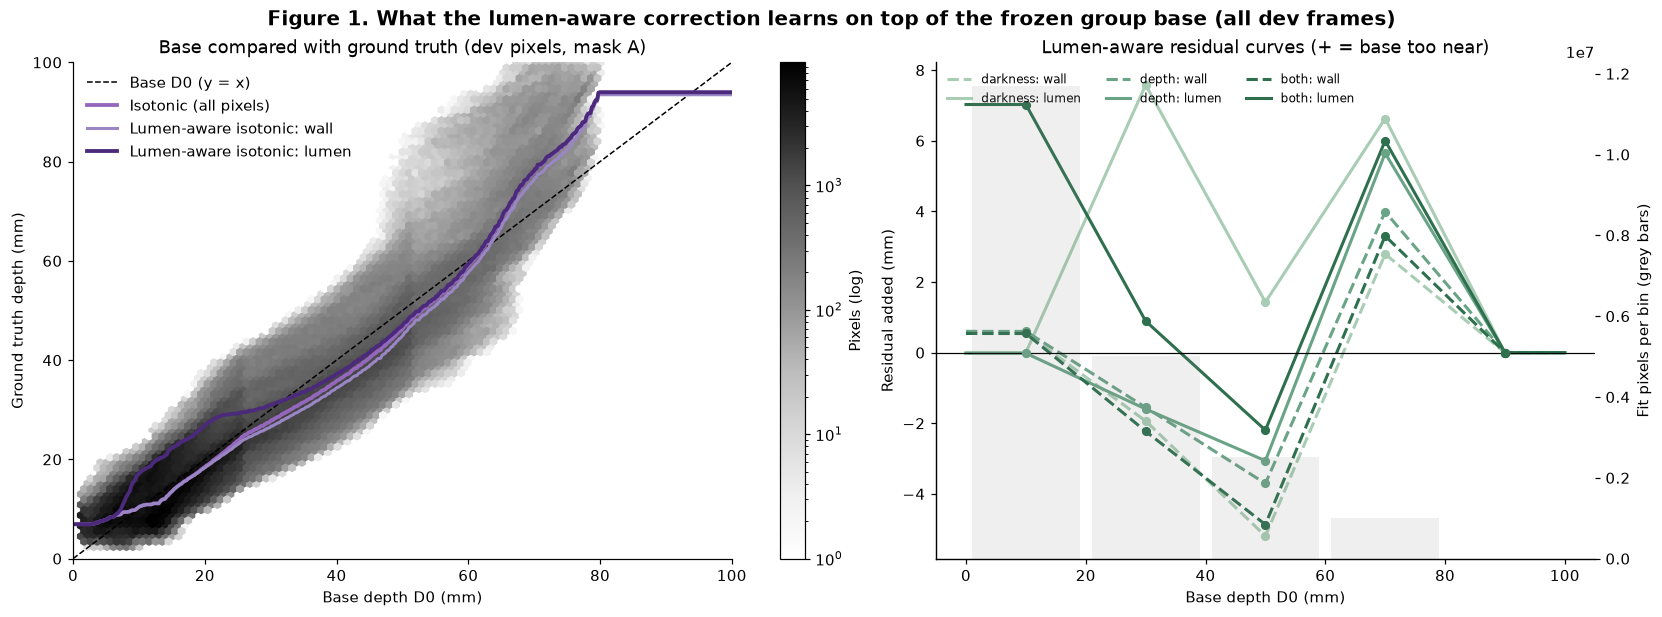

In [9]:
P_all = fit_all(list(range(len(FR))), FROZEN)

xs, ys = [], []
for F in FR:
    m = F["mask"]["A"]
    xs.append(apply_smooth(F["pred"], FROZEN)[m][::40]); ys.append(F["gt"][m][::40])
x, y = np.concatenate(xs), np.concatenate(ys)
g = np.linspace(0, DMAX, 500)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
hb = axes[0].hexbin(x, y, gridsize=80, bins="log", cmap="Greys", mincnt=1)
fig.colorbar(hb, ax=axes[0], label="Pixels (log)")
axes[0].plot(g, g, "--", color="black", lw=1, label="Base D0 (y = x)")
axes[0].plot(g, np.exp(P_all["iso"].predict(g)), color=COLORS["+ isotonic (log)"], lw=2.5, label="Isotonic (all pixels)")
axes[0].plot(g, np.exp(P_all["iso_wall"].predict(g)), color="#9a86c4", lw=2, label="Lumen-aware isotonic: wall")
axes[0].plot(g, np.exp(P_all["iso_lumen"].predict(g)), color=COLORS[FINAL], lw=2.5, label="Lumen-aware isotonic: lumen")
axes[0].set(xlabel="Base depth D0 (mm)", ylabel="Ground truth depth (mm)", xlim=(0, DMAX), ylim=(0, DMAX),
            title="Base compared with ground truth (dev pixels, mask A)")
axes[0].legend(frameon=False, loc="upper left")

for c in CUES:
    label = next(l for l, k, cue in METHODS if k == "resid" and cue == c)
    for part, ls in [("wall", "--"), ("lumen", "-")]:
        cy = P_all["curves"][f"{part}_{c}"]
        axes[1].plot(g, np.interp(g, CENTERS, cy), ls, color=COLORS[label], lw=2, label=f"{label.split('(')[1][:-1]}: {part}")
        axes[1].scatter(CENTERS, cy, color=COLORS[label], s=25, zorder=3)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel="Base depth D0 (mm)", ylabel="Residual added (mm)",
            title="Lumen-aware residual curves (+ = base too near)")
ax2 = axes[1].twinx()
ax2.bar(CENTERS, P_all["counts"]["wall_both"] + P_all["counts"]["lumen_both"], width=18, alpha=0.12, color="grey")
ax2.set_ylabel("Fit pixels per bin (grey bars)"); ax2.spines["top"].set_visible(False)
axes[1].legend(frameon=False, loc="upper left", ncol=3, fontsize=8)
fig.suptitle("Figure 1. What the lumen-aware correction learns on top of the frozen group base (all dev frames)",
             fontsize=13, fontweight="bold")
plt.savefig(fig_dir / "fig1_correction_curves.png", dpi=200, bbox_inches="tight"); plt.show()

### 8.2 Held-out AbsRel per fold
Figure 2 shows the mean held-out AbsRel (mask A) of each method in each fold.

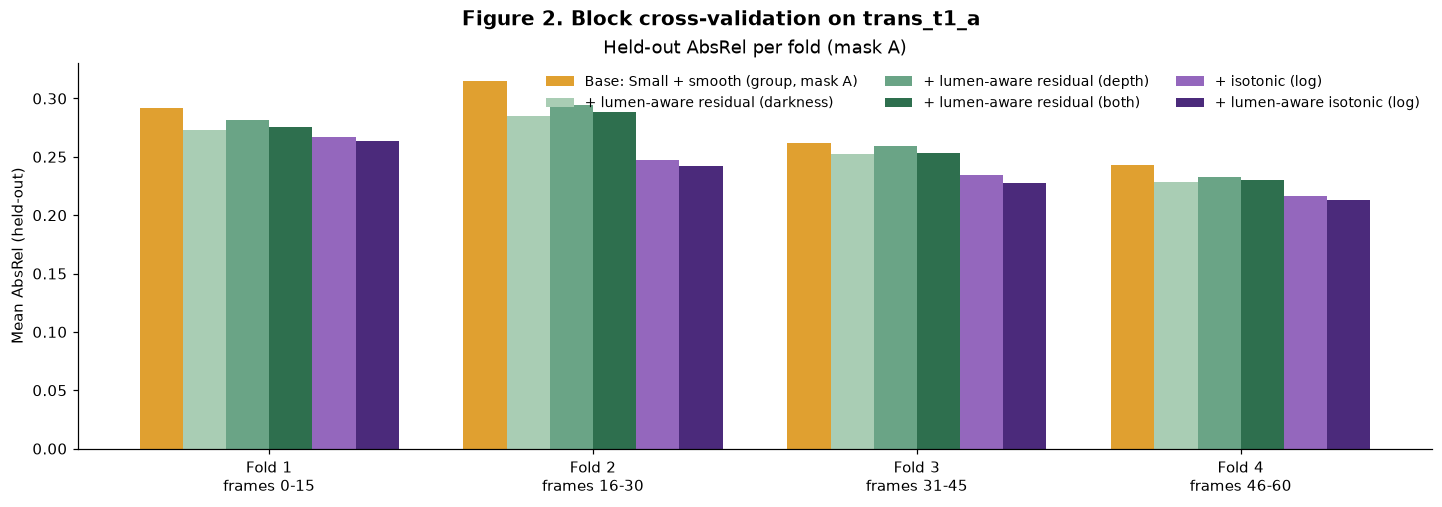

In [10]:
fold_ab = per_frame[per_frame["mask"] == "A"].groupby(["method", "fold"]).absrel.mean().unstack().loc[LABELS]
xf = np.arange(N_BLOCKS); wdt = 0.8 / len(LABELS)

fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
for j, label in enumerate(LABELS):
    ax.bar(xf + (j - (len(LABELS) - 1) / 2) * wdt, fold_ab.loc[label], wdt, color=COLORS[label], label=label)
ax.set_xticks(xf)
ax.set_xticklabels([f"Fold {k + 1}\nframes {h[0]}-{h[-1]}" for k, (_, h) in enumerate(FOLDS)])
ax.set(ylabel="Mean AbsRel (held-out)", title="Held-out AbsRel per fold (mask A)")
ax.legend(frameon=False, ncol=3, fontsize=9)
fig.suptitle("Figure 2. Block cross-validation on trans_t1_a", fontsize=13, fontweight="bold")
plt.savefig(fig_dir / "fig2_cv_folds.png", dpi=200, bbox_inches="tight"); plt.show()

### 8.3 Example frames
Figure 3 shows the best, median and worst held-out dev frames for the final method (mask A), each with the
parameters of the fold that held it out.

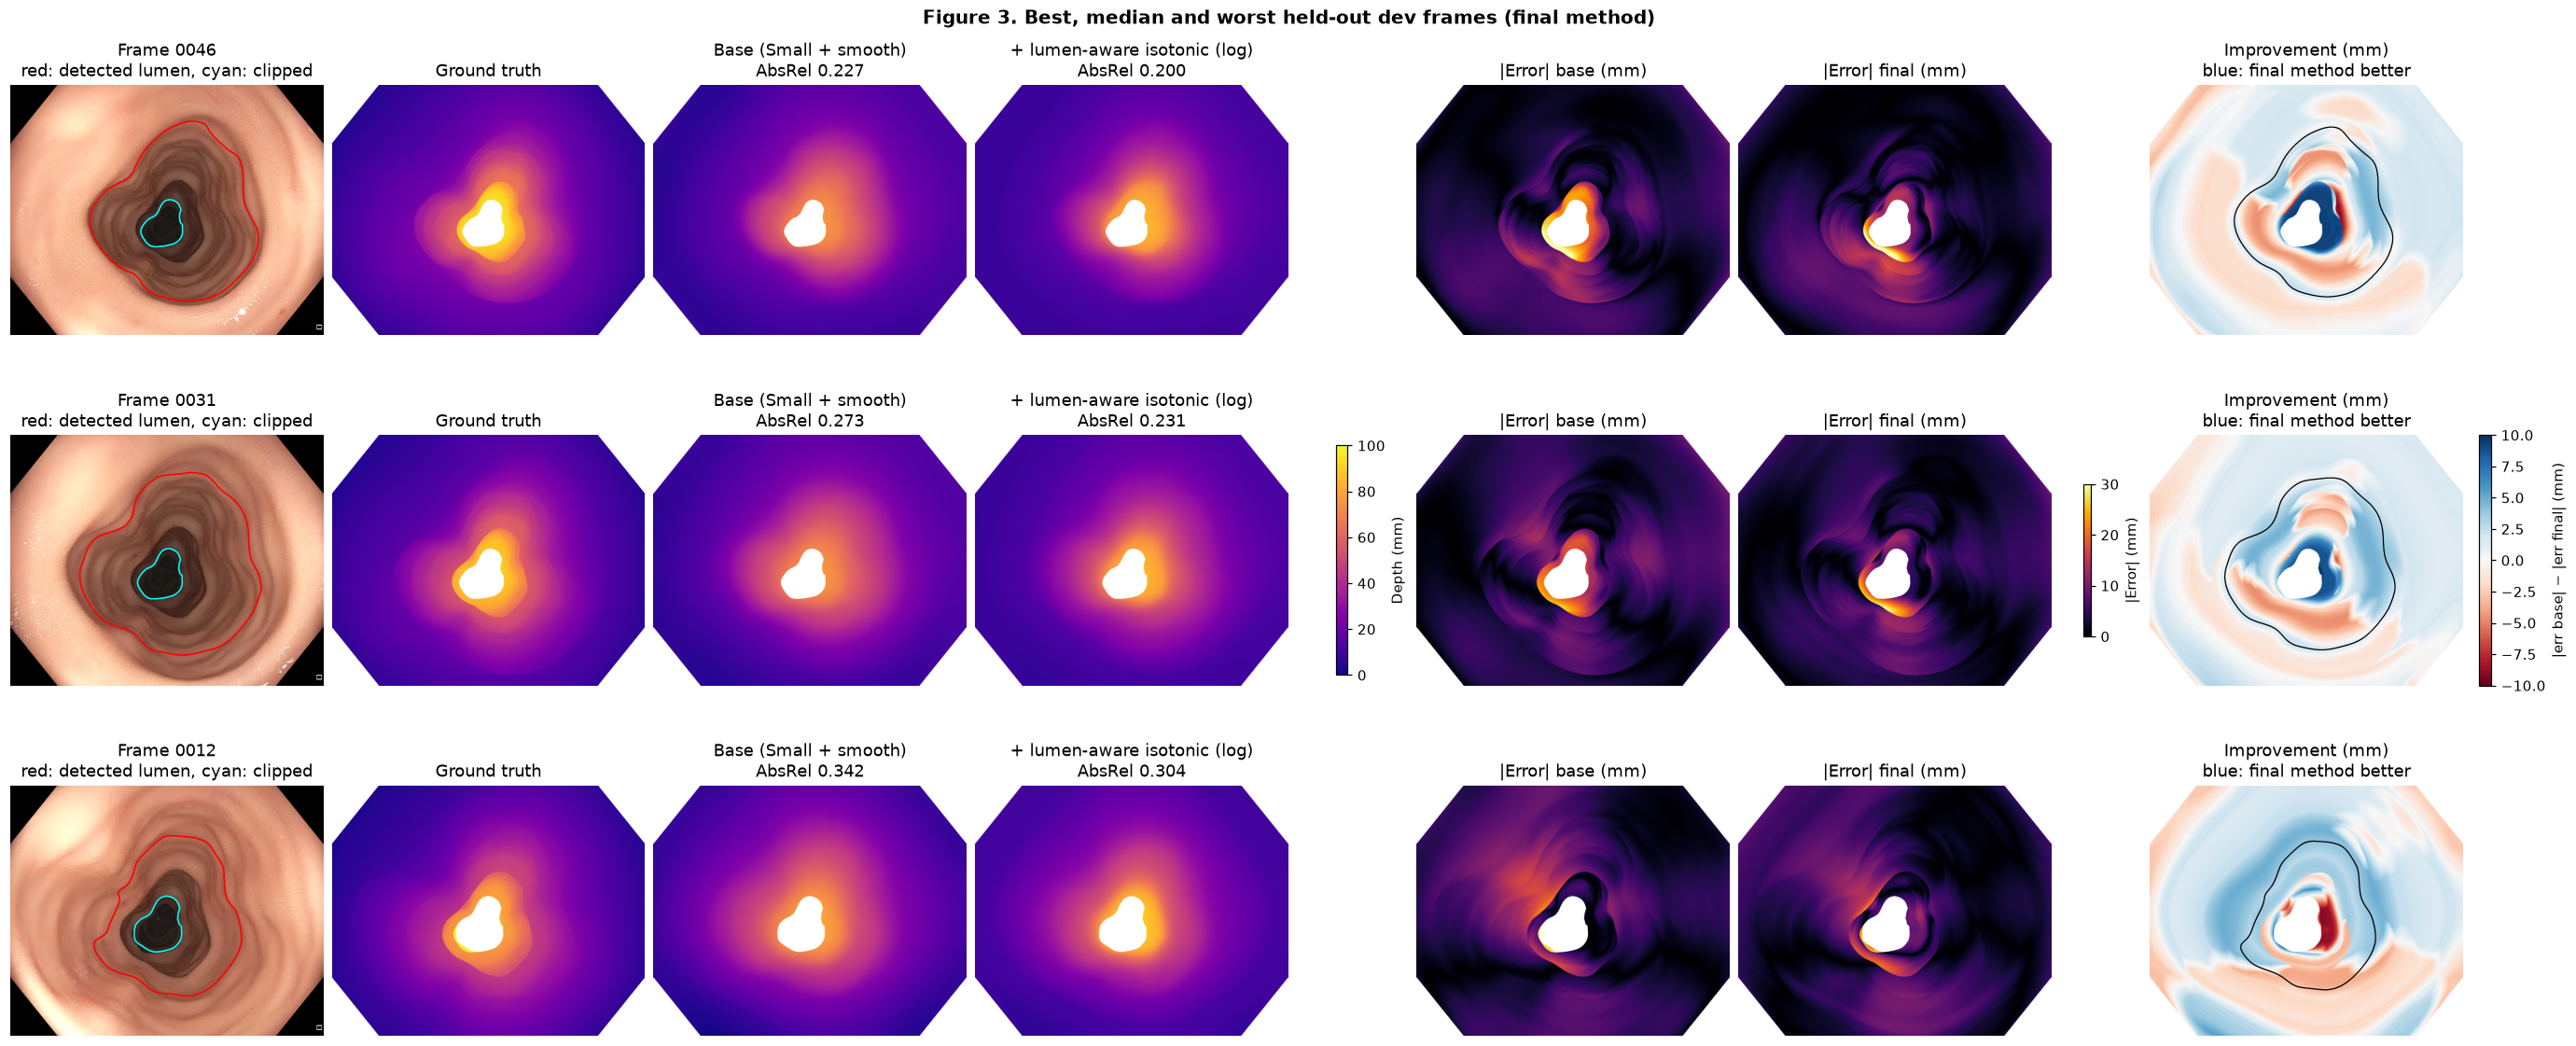

In [11]:
def nanv(a, F):
    return np.where(F["mask"]["A"], a, np.nan)


def fig_examples(frames, params, title, fname):
    fig, axes = plt.subplots(len(frames), 7, figsize=(25, 3.5 * len(frames)), constrained_layout=True)
    axes = np.atleast_2d(axes)
    for r, (F, P) in enumerate(zip(frames, params)):
        v = F["mask"]["A"]
        base, fin = predict("base", F, P), predict("iso_lumen", F, P, "both")
        es, ef = np.abs(base - F["gt"]), np.abs(fin - F["gt"])
        ax = axes[r]
        ax[0].imshow(F["rgb"])
        ax[0].contour(F["core"], colors="red", linewidths=1)
        ax[0].contour(F["clipped"], colors="cyan", linewidths=1)
        ax[0].set_title(f"Frame {F['name']}\nred: detected lumen, cyan: clipped")
        for j, (d, t) in enumerate([(F["gt"], "Ground truth"),
                                    (base, f"Base (Small + smooth)\nAbsRel {compute_metrics(base, F['gt'], v)['absrel']:.3f}"),
                                    (fin, f"{FINAL}\nAbsRel {compute_metrics(fin, F['gt'], v)['absrel']:.3f}")], start=1):
            im_d = ax[j].imshow(nanv(d, F), cmap="plasma", vmin=0, vmax=DMAX); ax[j].set_title(t)
        im_e = ax[4].imshow(nanv(es, F), cmap="inferno", vmin=0, vmax=30); ax[4].set_title("|Error| base (mm)")
        ax[5].imshow(nanv(ef, F), cmap="inferno", vmin=0, vmax=30); ax[5].set_title("|Error| final (mm)")
        im_i = ax[6].imshow(nanv(es - ef, F), cmap="RdBu", norm=TwoSlopeNorm(0, -10, 10))
        ax[6].contour(F["w"]["both"].astype(np.float32) > 0.5, colors="black", linewidths=0.8)
        ax[6].set_title("Improvement (mm)\nblue: final method better")
        for a in ax:
            a.axis("off")
    fig.colorbar(im_d, ax=axes[:, 1:4], fraction=0.012, label="Depth (mm)")
    fig.colorbar(im_e, ax=axes[:, 4:6], fraction=0.012, label="|Error| (mm)")
    fig.colorbar(im_i, ax=axes[:, 6], fraction=0.04, label="|err base| − |err final| (mm)")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.savefig(fig_dir / fname, dpi=200, bbox_inches="tight"); plt.show()


order = per_frame[(per_frame.method == FINAL) & (per_frame["mask"] == "A")].set_index("idx").absrel.sort_values()
pick = [order.index[0], order.index[len(order) // 2], order.index[-1]]
fig_examples([FR[i] for i in pick], [FOLD_PARAMS[HELD[i]] for i in pick],
             "Figure 3. Best, median and worst held-out dev frames (final method)", "fig3_dev_examples.png")

### 8.4 Save dev results
Saves the parameters fitted on all dev frames (used for the test), the group summary table and `run_info.json`.
Skipped once the test has run (the saved files, with the test rows, are kept).

In [12]:
iso_to_dict = lambda m: {"x": m.X_thresholds_.tolist(), "log_depth": m.y_thresholds_.tolist()}
base_to_dict = lambda b: {"scale": b["scale"], "offset": b["offset"], "centers": np.asarray(b["centers"]).tolist(),
                          "corrections": np.asarray(b["corrections"]).tolist()}


def group_rows(tab, split):
    return [{"model": f"DAv2 Small + smooth {r.method}" if r.method != BASE else "DAv2 Small + smooth (group base)",
             "output_type": "disparity", "alignment": "global_lsq + smooth",
             "fit_on": "dev_blocks_cv" if split == "dev" else "dev_all (base: frozen mask-A group params)",
             "split": split, "mask": r.mask, "n_frames": r.n_frames,
             "absrel": r.absrel, "rmse": r.rmse, "mae": r.mae, "delta1": r.delta1} for r in tab.itertuples()]


if TEST_DONE.exists():
    print(f"Test already run: dev results not re-saved (kept in {out_dir})")
else:
    with open(out_dir / "params_dev.json", "w") as f:
        json.dump({"base_frozen": base_to_dict(FROZEN), "base_source": str(BASE_PARAMS.relative_to(REPO_ROOT)),
                   "base_refit_all_dev": base_to_dict(BASE_ALL_DEV),
                   "base_per_fold": [base_to_dict(P["base"]) for P in FOLD_PARAMS],
                   "sigma": SIGMA, "tau": TAU, "bin_edges": BIN_EDGES.tolist(), "centers": CENTERS.tolist(),
                   "min_pixels": MIN_PIXELS, "fit_stride": FIT_STRIDE, "iso_stride": ISO_STRIDE,
                   "curves_all_dev": {k: v.tolist() for k, v in P_all["curves"].items()},
                   "isotonic_all_dev": {k: iso_to_dict(P_all[k]) for k in ["iso", "iso_wall", "iso_lumen"]}}, f, indent=2)
    save_summary(group_rows(abl, "dev"), out_dir, RUN_NAME)
    save_run_info(out_dir, DEVICE, SEED, extra={"base_model": "DAv2 Small 518 + smooth correction, fitted on mask-A pixels "
                                                               "(group base, DAv2_MaskA_Verified)",
                                                 "base_params": str(BASE_PARAMS.relative_to(REPO_ROOT)),
                                                 "input_size": INPUT_SIZE, "sigma": SIGMA, "tau": TAU,
                                                 "n_blocks": N_BLOCKS, "gap": GAP, "masks": MASKS})
    print(f"Saved dev results to {out_dir}")

Test already run: dev results not re-saved (kept in /Users/aditiraghu/c3vd/results/LumenAware_on_SmallSmooth)


## 9. Test (trans_t2_b) — run once
Base = frozen mask-A group parameters (`calibration_parameters_maskA.json`); methods 1–5 = `P_all` (fitted on all
61 dev frames). Check (b) runs first: the base alone on test (mask A, frame mean) must give AbsRel 0.2805;
otherwise the cell stops before the methods are evaluated. The test runs only if `RUN_TEST` is True and
`test_done.json` does not exist. If the test already ran, the cell loads the saved `per_frame_test.csv` and
`test_summary.csv` (and the test frames, from the prediction cache, for Figure 4) and repeats check (b) from the saved
base row; the model is not run. Table 2 shows mask A (mask-B results are in `test_summary.csv`).

In [13]:
if TEST_DONE.exists():
    done = json.load(open(TEST_DONE))
    print(f"Test already run on {done['date']}: showing the saved results.")
    test_pf = pd.read_csv(out_dir / "per_frame_test.csv", dtype={"frame": str})   # keep "0066"
    test_tab = pd.read_csv(out_dir / "test_summary.csv")
    TE = load_frames(test_paths, "test")             # cached predictions (for Figure 4); the model is not run
    base_ab = test_tab[(test_tab["mask"] == "A") & (test_tab.method == BASE)].absrel.item()
    print(f"Check (b): base on test, mask A, frame mean AbsRel = {base_ab:.4f} (expected 0.2805) "
          f"{'passed' if round(base_ab, 4) == 0.2805 else 'FAILED'}")
elif not RUN_TEST:
    print("RUN_TEST is False: the test was not run. Set RUN_TEST = True in Section 1 for the final run.")
else:
    TE = load_frames(test_paths, "test")

    base_ab = np.mean([compute_metrics(apply_smooth(F["pred"], FROZEN), F["gt"], F["mask"]["A"])["absrel"] for F in TE])
    print(f"Check (b): base on test, mask A, frame mean AbsRel = {base_ab:.4f} (expected 0.2805)")
    if round(base_ab, 4) != 0.2805:
        raise RuntimeError("Check (b) failed: the base on test does not match DAv2_MaskA_Verified. Test not evaluated.")
    print("Check (b) passed.")

    test_rows = []
    for F in TE:
        test_rows += eval_frame(F, P_all, {})
    test_pf = pd.DataFrame(test_rows)
    test_tab = summarise(test_pf)
    test_pf.to_csv(out_dir / "per_frame_test.csv", index=False)
    test_tab.to_csv(out_dir / "test_summary.csv", index=False)
    save_summary(group_rows(abl, "dev") + group_rows(test_tab, "test"), out_dir, RUN_NAME)

    T = test_tab[test_tab["mask"] == "A"].set_index("method")

    with open(TEST_DONE, "w") as f:
        json.dump({"date": datetime.now().isoformat(timespec="seconds"), "n_frames": len(TE),
                   "absrel_mask_A": T.absrel.to_dict()}, f, indent=2)
    print(f"Test done. Saved to {out_dir}")

if "test_tab" in globals():
    show_table(test_tab[test_tab["mask"] == "A"],
               f"Table 2. Test results on trans_t2_b ({len(TE)} frames), mask A; frozen base, methods 1–5 fitted on all dev")
    T = test_tab[test_tab["mask"] == "A"].set_index("method")
    for label in LABELS[1:]:
        print(f"{label:36s}: AbsRel {T.absrel[BASE]:.4f} -> {T.absrel[label]:.4f} (gain {T.absrel[BASE] - T.absrel[label]:+.4f})")

Test already run on 2026-11-01T14:32:32: showing the saved results.


test frames:   0%|          | 0/103 [00:00<?, ?it/s]

test frames:   1%|          | 1/103 [00:00<00:31,  3.23it/s]

test frames:   2%|▏         | 2/103 [00:00<00:31,  3.23it/s]

test frames:   3%|▎         | 3/103 [00:00<00:30,  3.25it/s]

...

test frames: 100%|██████████| 103/103 [00:32<00:00,  3.18it/s]

test frames: 100%|██████████| 103/103 [00:32<00:00,  3.19it/s]

Check (b): base on test, mask A, frame mean AbsRel = 0.2805 (expected 0.2805) passed


Method,AbsRel ↓,RMSE (mm) ↓,MAE (mm) ↓,δ<1.25 ↑,AbsRel wall ↓,AbsRel lumen ↓
"Base: Small + smooth (group, mask A)",0.281,5.60,4.41,0.535,0.327,0.102
+ lumen-aware residual (darkness),0.261,5.06,4.09,0.569,0.302,0.101
+ lumen-aware residual (depth),0.264,5.19,4.21,0.563,0.304,0.108
+ lumen-aware residual (both),0.260,5.10,4.11,0.573,0.301,0.102
+ isotonic (log),0.205,4.84,3.80,0.611,0.227,0.117
+ lumen-aware isotonic (log),0.201,4.72,3.69,0.628,0.224,0.109


+ lumen-aware residual (darkness)   : AbsRel 0.2805 -> 0.2607 (gain +0.0198)
+ lumen-aware residual (depth)      : AbsRel 0.2805 -> 0.2636 (gain +0.0169)
+ lumen-aware residual (both)       : AbsRel 0.2805 -> 0.2602 (gain +0.0204)
+ isotonic (log)                    : AbsRel 0.2805 -> 0.2051 (gain +0.0755)
+ lumen-aware isotonic (log)        : AbsRel 0.2805 -> 0.2008 (gain +0.0797)


### 9.1 Test example frames
Figure 4 shows the best, median and worst test frames for the final method. It needs the test results (run or loaded)
by the test cell above.

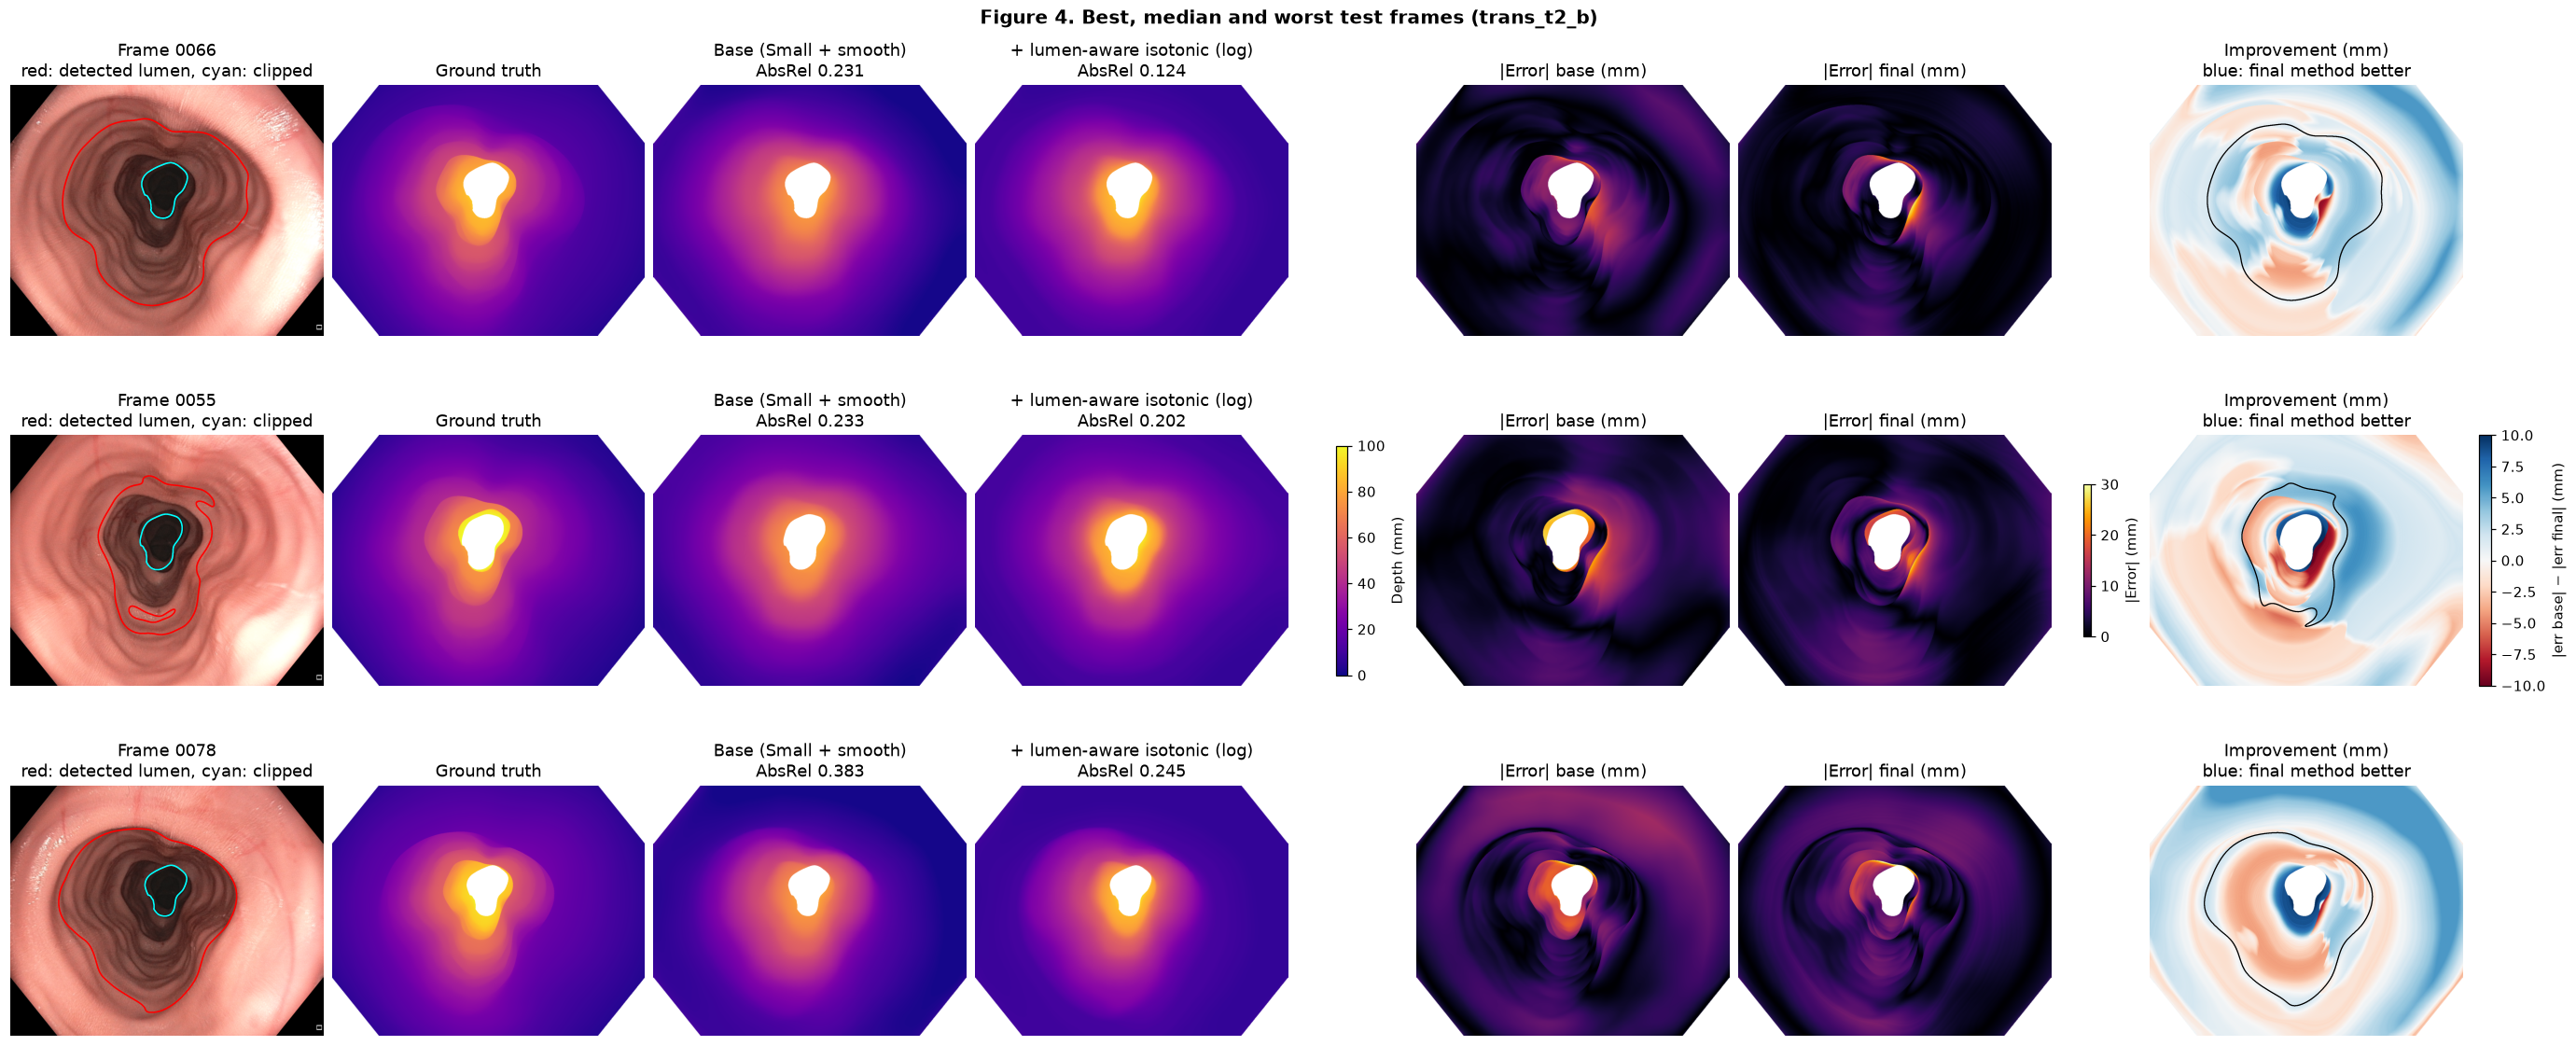

In [14]:
if "test_pf" not in globals():
    print("Run the test cell (Section 9) first.")
else:
    order_t = test_pf[(test_pf.method == FINAL) & (test_pf["mask"] == "A")].set_index("frame").absrel.sort_values()
    name_to_F = {F["name"]: F for F in TE}
    pick_t = [order_t.index[0], order_t.index[len(order_t) // 2], order_t.index[-1]]
    fig_examples([name_to_F[n] for n in pick_t], [P_all] * 3,
                 "Figure 4. Best, median and worst test frames (trans_t2_b)", "fig4_test_examples.png")